# Machine Learning #06 — Recurrent Neural Networks in PyTorch 🔁
Today we move to **Recurrent Neural Networks (RNNs)** — networks that have a **memory** and can
process **sequences** (text, time series, audio…).

Our task: **classify tweets** as *racist/sexist* (`1`, the dataset's hate-speech
label) or *other* (`0`).

We will walk through the **complete PyTorch sequence workflow**:

> **raw text → clean tokens → vocabulary → padded tensors → embedding → RNN (LSTM + GRU) → prediction**

## What is an RNN? 🧠

### 1. How is an RNN different from a feed-forward network (FCNN)?

A fully connected feed-forward network maps a fixed-size input to an output. It
can use position-specific features, but has no recurrent state passed between time
steps. An **RNN has a memory**: a **hidden state**
$h_t$ that is passed from one step of the sequence to the next.

$$h_t = f(W_x\,x_t + W_h\,h_{t-1} + b)$$

Thanks to this loop it can capture **dependencies over time** — for example that
the word *"not"* before *"good"* flips the whole meaning of a sentence.

| | Feed-forward (FCNN) | Recurrent (RNN) |
|---|---|---|
| Input | one fixed vector | a **sequence** of vectors |
| Memory | none | **hidden state** carried step by step |
| Typical use | tabular data | text, time series, speech |

### 2. Pure RNN vs. LSTM / GRU — what problem do they solve?

A **plain RNN** can suffer from **vanishing or exploding gradients** when
back-propagating through many time steps. Vanishing gradients make long-range
dependencies difficult to learn.

- **LSTM** (Long Short-Term Memory) uses **input, forget, and output gates** and a
  separate **cell state** $c_t$ to make retaining information easier. 🔒
- **GRU** (Gated Recurrent Unit) uses **reset and update gates** and one hidden
  state. It has fewer parameters than an LSTM with the same input and hidden sizes. ⚡

Gating helps with long-range learning, but does not eliminate all gradient problems.
Which architecture works better depends on the task and training setup.

## Imports and setup ⚙️

Remember to switch the Colab runtime to **GPU**! *(Runtime → Change runtime type → GPU)*

The setup cell installs TextBlob and NLTK. Both are also included in the project's
local dependencies. We use tokenization only, so no WordNet lemmatizer is needed.

In [ ]:
%pip install "textblob>=0.19" "nltk>=3.9" -q

In [ ]:
import unicodedata, re, string, itertools

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import nltk
from textblob import TextBlob

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torch.nn.utils.rnn import pad_sequence, pack_padded_sequence

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, classification_report

sns.set_theme(style="whitegrid")

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("torch version:", torch.__version__)
print("device:", device)

In [ ]:
# TextBlob's word tokenization uses NLTK's Punkt sentence tokenizer.
# Install its data separately from the Python packages.
nltk.download("punkt_tab", raise_on_error=True)

## How an LSTM sees a sequence 🔬

Before touching real data, let's understand **the shapes**.

For a **unidirectional LSTM without projection**, `batch_first=True` means the input is:

$$(\text{batch},\ \text{sequence length},\ \text{features})$$

It returns:

- **`output`** — the last recurrent layer's hidden state at **every** time step,
  with shape `(batch, seq_len, hidden)`.
- **`(h_n, c_n)`** — the **final** hidden and cell states for **each layer**,
  both with shape `(num_layers, batch, hidden)`.

For a bidirectional LSTM, `output` has `2 * hidden` features and the state tensors
have `2 * num_layers` entries on the first axis. `batch_first` does not change the
layout of `h_n` and `c_n`.

See the [PyTorch LSTM documentation](https://docs.pytorch.org/docs/stable/generated/torch.nn.LSTM.html).

In [3]:
# A fake "batch of 2 sequences, each 4 steps long, each step a 3-number vector"
demo_lstm = nn.LSTM(input_size=3, hidden_size=5, batch_first=True)

dummy = torch.randn(2, 4, 3)          # (batch=2, seq_len=4, features=3)
output, (h_n, c_n) = demo_lstm(dummy)

print("input   :", tuple(dummy.shape),  "-> (batch, seq_len, features)")
print("output  :", tuple(output.shape), "-> hidden state at EVERY step")
print("h_n     :", tuple(h_n.shape),    "-> LAST hidden state (a summary of the whole sequence)")
print("c_n     :", tuple(c_n.shape),    "-> LAST cell state (LSTM's long-term memory)")

input   : (2, 4, 3) -> (batch, seq_len, features)
output  : (2, 4, 5) -> hidden state at EVERY step
h_n     : (1, 2, 5) -> LAST hidden state (a summary of the whole sequence)
c_n     : (1, 2, 5) -> LAST cell state (LSTM's long-term memory)


> 💡 For sequence classification, we can use the **top layer's final hidden state**
> (`h_n[-1]` for a unidirectional RNN) as a summary of each sequence, then feed it to
> a classifier. The hidden state is reset between independent tweets in this notebook.

## The dataset 📊

We use `train_tweets.csv` from the course repository, corresponding to the
[Analytics Vidhya Twitter classification task](https://www.analyticsvidhya.com/blog/2018/07/hands-on-sentiment-analysis-dataset-python/).
That task defines its positive hate-speech label as **racist or sexist content**.

| Column | Meaning |
|---|---|
| `tweet` | raw tweet text |
| `label` | `1` = racist/sexist, `0` = other tweets |

Class `0` is not a neutral-sentiment label: those tweets can express positive or
negative sentiment.

In [4]:
df = pd.read_csv("https://github.com/rasvob/VSB-FEI-Deep-Learning-Exercises/raw/main/datasets/train_tweets.csv")
df.head()

,id,label,tweet
0,1,0,@user when a father is dysfunctional and is s...
1,2,0,@user @user thanks for #lyft credit i can't us...
2,3,0,bihday your majesty
3,4,0,#model i love u take with u all the time in ...
4,5,0,factsguide: society now #motivation


In [5]:
df.shape

(31962, 3)

### 🔎 A quick look — how imbalanced is it?

In [ ]:
sns.countplot(x="label", data=df)
plt.title("Class distribution (0 = other, 1 = racist/sexist)")
plt.show()

print(df.label.value_counts())

### 🔎 Compare tweet lengths by class

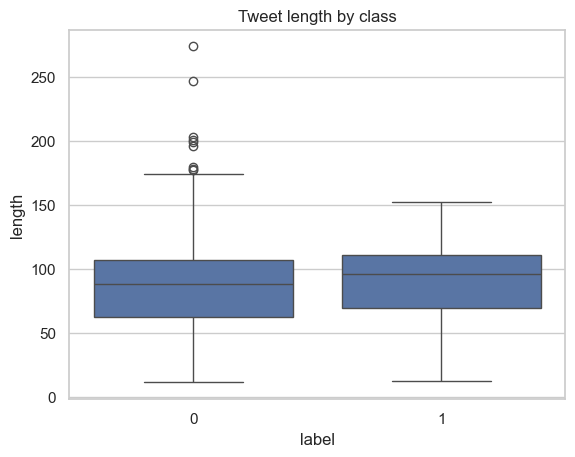

In [7]:
df["length"] = df.tweet.apply(len)
sns.boxplot(x="label", y="length", data=df)
plt.title("Tweet length by class")
plt.show()

### The raw text is very noisy

Take a look at a few examples — mentions (`@user`), punctuation, weird casing,
contractions… This is why we need a preprocessing pipeline.

In [8]:
for t in df.loc[:10, "tweet"]:
    print(t)

 @user when a father is dysfunctional and is so selfish he drags his kids into his dysfunction.   #run
@user @user thanks for #lyft credit i can't use cause they don't offer wheelchair vans in pdx.    #disapointed #getthanked
  bihday your majesty
#model   i love u take with u all the time in urð±!!! ððððð¦ð¦ð¦  
 factsguide: society now    #motivation
[2/2] huge fan fare and big talking before they leave. chaos and pay disputes when they get there. #allshowandnogo  
 @user camping tomorrow @user @user @user @user @user @user @user dannyâ¦
the next school year is the year for exams.ð¯ can't think about that ð­ #school #exams   #hate #imagine #actorslife #revolutionschool #girl
we won!!! love the land!!! #allin #cavs #champions #cleveland #clevelandcavaliers  â¦ 
 @user @user welcome here !  i'm   it's so #gr8 ! 
 â #ireland consumer price index (mom) climbed from previous 0.2% to 0.5% in may   #blog #silver #gold #forex


## Text preprocessing 🧹

We turn each tweet into a **list of tokens (words)**. We apply these fixed rules:

1. **Tokenize** the tweet into words with TextBlob.
2. **Normalize Unicode to ASCII**: accented letters may simplify (e.g. `é → e`),
   while unsupported characters are removed.
3. **Lowercase** everything.
4. **Remove digits** from tokens.
5. **Strip leading and trailing punctuation** and drop tokens that become empty.
   Internal punctuation such as the apostrophe in `don't` is retained.
6. **Remove exactly `user`**, the token left by this dataset's anonymized `@user`
   mentions. Words such as `abuser` must remain.
7. **Join split negative contractions**, such as `do` + `n't` → `don't`.

These are simple baseline rules. Numbers, emoji, and punctuation can carry useful
information; compare alternative preprocessing choices using validation data.

In [ ]:
def form_sentence(tweet):
    """Tokenize a raw tweet into a list of words using TextBlob."""
    return list(TextBlob(tweet).words)

def remove_non_ascii(words):
    """Simplify Unicode where possible, then discard remaining non-ASCII characters."""
    out = []
    for w in words:
        w = unicodedata.normalize("NFKD", w).encode("ascii", "ignore").decode("utf-8", "ignore")
        out.append(w)
    return out

def to_lowercase(words):
    return [w.lower() for w in words]

def remove_numbers(words):
    """Remove digits; keep the word only if something is left."""
    out = []
    for w in words:
        w = re.sub(r"\d+", "", w)
        if w != "":
            out.append(w)
    return out

def remove_punctuation(words):
    """Strip leading/trailing punctuation from each token; drop tokens left empty."""
    out = []
    for w in words:
        w = w.strip(string.punctuation)
        if w != "":
            out.append(w)
    return out

def normalize(words):
    words = remove_non_ascii(words)
    words = to_lowercase(words)
    words = remove_numbers(words)
    words = remove_punctuation(words) 
    return words

def fix_nt(words):
    """Merge a stray "n't" back onto the previous word: [do, n't] -> [don't]."""
    res = []
    for w in words:
        if w in ("n't", "nt") and res:
            res[-1] = res[-1] + "n't"   # attach onto the previous word
        else:
            res.append(w)
    return res

### Apply the pipeline step by step 🧼

We build up new columns so you can **see** the effect of each stage.

In [ ]:
# 1) tokenize
df["Words"] = df["tweet"].apply(form_sentence)
df.loc[:5,  ["tweet", "Words"]]

In [ ]:
# 2-5) normalize (non-ascii, lowercase, numbers, punctuation)
df["Words_normalized"] = df["Words"].apply(normalize)
df.loc[:5,  ["tweet", "Words", "Words_normalized"]]

In [ ]:
# 6) remove the 'user' token
df["Words_normalized_no_user"] = df["Words_normalized"].apply(lambda ws: [w for w in ws if w != "user"])
df.loc[:5,  ["tweet", "Words_normalized", "Words_normalized_no_user"]]

In [ ]:
# 7) fix contractions
df["Words_clean"] = df["Words_normalized_no_user"].apply(fix_nt)

df.loc[:5, ["tweet", "Words_normalized_no_user", "Words_clean"]]

> 💡 Each tweet is now a **clean list of tokens**. This list-of-tokens form is
> exactly what we need to build a vocabulary next.

### Train / validation / test split 🎯

First remove tweets that became empty during cleaning: packed RNN inputs require
positive lengths. Then split **with stratification**, before counting vocabulary words.

We reserve 20% for testing, then use 10% of the remaining 80% for validation. The final
proportions are approximately **72% training, 8% validation, and 20% test**.

In [ ]:
# Remove empty token lists before splitting and building the training vocabulary.
nonempty = df["Words_clean"].apply(len) > 0
print("Dropping empty tweets:", int((~nonempty).sum()))
df = df.loc[nonempty].copy()

# Stratified split: 80% train+val, 20% test.
X_train, X_test, y_train, y_test = train_test_split(
    df.Words_clean, df.label, test_size=0.20, random_state=SEED, stratify=df.label
)
# Take 10% of the remaining 80% for validation: 72/8/20 overall.
X_train, X_val, y_train, y_val = train_test_split(
    X_train, y_train, test_size=0.10, random_state=SEED, stratify=y_train
)

print("train:", len(X_train), "| val:", len(X_val), "| test:", len(X_test))
print("\nTrain label counts:\n", y_train.value_counts())

## A look at the training vocabulary 🔤

Count words in **training tweets only**. Validation and test tweets must not determine
which words are kept or how often they occur.

In [ ]:
all_words = list(itertools.chain.from_iterable(X_train))
all_words[:20]

In [ ]:
dist = nltk.FreqDist(all_words)
dist

In [ ]:
print("Training tokens :", len(all_words))
print("Unique training tokens:", len(dist))
print("Longest training tweet:", max(X_train.apply(len)), "tokens")

## From words to numbers 🔢

The network works with **integers**, not strings. We build a **vocabulary** that
maps each word to an index. Two indices are special:

| Index | Token | Meaning |
|---|---|---|
| `0` | `<pad>` | padding (to make sequences equal length) |
| `1` | `<unk>` | unknown word (not in the vocabulary / rare) |

`VOCAB_SIZE` is the maximum total size, **including the two special tokens**.
We keep up to `VOCAB_SIZE - 2` words from the training set; rare or unseen words
become `<unk>`. The vocabulary stays fixed for validation and test data.

This is the manual PyTorch equivalent of Keras' `TextVectorization` layer.

In [ ]:
VOCAB_SIZE = 10000        # at most 9,998 training words + 2 special tokens
PAD_TOKEN, UNK_TOKEN = "<pad>", "<unk>"

# most common words first, leaving room for the 2 special tokens
most_common = [w for w, _ in dist.most_common(VOCAB_SIZE - 2)]
vocab = [PAD_TOKEN, UNK_TOKEN] + most_common

word2idx = {w: i for i, w in enumerate(vocab)}
PAD_IDX = word2idx[PAD_TOKEN]
UNK_IDX = word2idx[UNK_TOKEN]

print("Vocabulary size:", len(vocab))
print("First 10 tokens:", vocab[:10])

In [ ]:
def numericalize(tokens):
    """Convert a list of words into a list of integer indices."""
    return [word2idx.get(w, UNK_IDX) for w in tokens]

# quick check on one tweet
example = X_train.iloc[0]
print("tokens :", example)
print("indices:", numericalize(example))

## Dataset & DataLoader — batching variable-length sequences 📦

Tweets have **different lengths**, but a batch tensor must be **rectangular**.
The clean PyTorch solution has three parts:

1. A **`Dataset`** that returns one `(sequence, label)` at a time.
2. A **`collate_fn`** that, for each batch, **pads** the shorter sequences with
   `<pad>` so they all match the longest one — and records the **real lengths**.
3. Later, inside the model, we use **`pack_padded_sequence`** so the RNN
   **ignores the padding** and only processes the real tokens. This
   approach prevents trailing padding from changing the final recurrent states.
   It also avoids recurrent computations for padded time steps; actual speed depends
   on the device and sequence lengths.

In [ ]:
class TweetDataset(Dataset):
    def __init__(self, token_lists, labels):
        # store each tweet as a LongTensor of word indices (variable length)
        self.sequences = [torch.tensor(numericalize(toks), dtype=torch.long) for toks in token_lists]
        self.labels    = torch.tensor(list(labels), dtype=torch.float32)

    def __len__(self):
        return len(self.sequences)

    def __getitem__(self, i):
        return self.sequences[i], self.labels[i]

In [ ]:
def collate_fn(batch):
    """Turn a list of (sequence, label) into padded batch tensors."""
    sequences, labels = zip(*batch)
    lengths = torch.tensor([len(s) for s in sequences], dtype=torch.long)  # real length of each tweet
    # pad every sequence to the length of the longest one in THIS batch
    padded  = pad_sequence(sequences, batch_first=True, padding_value=PAD_IDX)
    labels  = torch.stack(labels).unsqueeze(1)   # shape (batch, 1) to match the model output
    return padded, lengths, labels

> ⚠️ Empty token lists were removed **before the split**. `pack_padded_sequence`
> requires strictly positive lengths; our batches now contain only nonempty sequences.

In [ ]:
BATCH_SIZE = 128

train_ds = TweetDataset(X_train, y_train)
val_ds   = TweetDataset(X_val,   y_val)
test_ds  = TweetDataset(X_test,  y_test)

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True,  collate_fn=collate_fn)
val_loader   = DataLoader(val_ds,   batch_size=BATCH_SIZE, shuffle=False, collate_fn=collate_fn)
test_loader  = DataLoader(test_ds,  batch_size=BATCH_SIZE, shuffle=False, collate_fn=collate_fn)

# peek at one batch
xb, lengths, yb = next(iter(train_loader))
print("padded batch :", tuple(xb.shape), "-> (batch, longest_seq_in_batch)")
print("lengths      :", tuple(lengths.shape), "e.g.", lengths[:5].tolist())
print("labels       :", tuple(yb.shape))

## Build the RNN 🏗️

Our model:

$$\text{indices} \rightarrow \textbf{Embedding} \rightarrow \textbf{LSTM} \rightarrow \textbf{GRU} \rightarrow \text{last hidden state} \rightarrow \textbf{Linear} \rightarrow \text{logit}$$

- **`nn.Embedding(vocab_size, embed_dim, padding_idx=PAD_IDX)`** — turns each word
  index into a trainable `embed_dim`-vector. `padding_idx` keeps the `<pad>`
  vector fixed at zero. 🎯
- **`nn.LSTM` → `nn.GRU`** — two stacked recurrent layers. The LSTM passes its
  full per-step output to the GRU (like `return_sequences=True`), and we take the
  GRU's **last hidden state** as the sequence summary (like `return_sequences=False`).
- Inside `forward` we **pack** the padded batch so the RNN skips `<pad>` tokens.

We write it as an **`nn.Module` class** because the packing
logic lives naturally inside `forward`.

In [ ]:
class RNNClassifier(nn.Module):
    def __init__(self, vocab_size, embed_dim, hidden_dim, pad_idx):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=pad_idx)
        self.lstm = nn.LSTM(embed_dim,  hidden_dim, batch_first=True)
        self.gru  = nn.GRU(hidden_dim,  hidden_dim, batch_first=True)
        self.fc1  = nn.Linear(hidden_dim, 64)
        self.drop = nn.Dropout(0.3)
        self.fc2  = nn.Linear(64, 1)      # single output logit

    def forward(self, x, lengths):
        emb = self.embedding(x)                              # (batch, seq, embed_dim)

        # PACK: tell the RNN the real length of each sequence so it ignores <pad>
        packed = pack_padded_sequence(emb, lengths.cpu(), batch_first=True, enforce_sorted=False)

        packed_out, _ = self.lstm(packed)                    # LSTM over the packed sequence
        _, h_n        = self.gru(packed_out)                 # GRU; h_n = last hidden state

        summary = h_n[-1]                                    # (batch, hidden) -> last layer's hidden state
        z = torch.relu(self.fc1(summary))
        z = self.drop(z)
        return self.fc2(z)                                   # (batch, 1) logit

In [ ]:
EMBED_DIM  = 128
HIDDEN_DIM = 64

model = RNNClassifier(len(vocab), EMBED_DIM, HIDDEN_DIM, PAD_IDX).to(device)
print(model)

n_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print("\nTrainable parameters:", f"{n_params:,}")

## Loss, optimizer & the training loop ⭐

- **`nn.BCEWithLogitsLoss`** — binary cross-entropy that takes **raw logits**
  (it applies the sigmoid internally, which is numerically stable).
- **`AdamW`** — Adam with proper weight decay; a solid modern default. ⚙️

The loop is the same idea as lesson #01, but now we iterate over **mini-batches**
from the `DataLoader`, and we **save the best model** (lowest validation loss).

In [ ]:
criterion = nn.BCEWithLogitsLoss()
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3)

N_EPOCHS = 5
history = {"train_loss": [], "val_loss": []}
best_val = float("inf")

for epoch in range(N_EPOCHS):
    # ---- training ----
    model.train()
    running = 0.0
    for xb, lengths, yb in train_loader:
        xb, yb = xb.to(device), yb.to(device)
        optimizer.zero_grad()
        logits = model(xb, lengths)
        loss = criterion(logits, yb)
        loss.backward()
        optimizer.step()
        running += loss.item() * xb.size(0)
    train_loss = running / len(train_loader.dataset)

    # ---- validation ----
    model.eval()
    running = 0.0
    with torch.no_grad():
        for xb, lengths, yb in val_loader:
            xb, yb = xb.to(device), yb.to(device)
            loss = criterion(model(xb, lengths), yb)
            running += loss.item() * xb.size(0)
    val_loss = running / len(val_loader.dataset)

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)

    # ---- checkpoint the best model ----
    if val_loss < best_val:
        best_val = val_loss
        torch.save(model.state_dict(), "best_scratch.pt")

    print(f"epoch {epoch+1:2d} | train {train_loss:.4f} | val {val_loss:.4f}")

# reload the best weights
model.load_state_dict(torch.load("best_scratch.pt", map_location=device, weights_only=True))

In [ ]:
plt.figure()
for key, values in history.items():
    plt.plot(values, marker="o", label=key)

plt.xlabel("Epoch")
plt.ylabel("Loss (BCE)")
plt.legend()
plt.tight_layout()
plt.show()

> 💡 A sustained increase in validation loss while training loss falls can indicate
> overfitting. We restore the checkpoint with the lowest validation loss.

## Evaluation 📈

For these fixed example configurations, we report **test-set** predictions using a
`0.5` probability threshold. Use **validation data** to choose architectures, training
settings, or a different threshold; then keep those choices fixed for final testing.

An always-class-0 prediction already has high accuracy because the dataset is imbalanced.
We therefore also report **F1 for the positive class (`1`)**, precision, recall, and a
confusion matrix. A majority-class baseline helps put the scores in context.

In [ ]:
def evaluate(model, loader, threshold=0.5):
    """Return (y_true, y_pred) over a whole DataLoader."""
    model.eval()
    y_true, y_pred = [], []
    with torch.no_grad():
        for xb, lengths, yb in loader:
            xb = xb.to(device)
            logits = model(xb, lengths)
            probs  = torch.sigmoid(logits).cpu().numpy().ravel()
            preds  = (probs >= threshold).astype(int)
            y_pred.extend(preds.tolist())
            y_true.extend(yb.numpy().ravel().astype(int).tolist())
    return np.array(y_true), np.array(y_pred)

y_true, y_pred = evaluate(model, test_loader)

print("Accuracy:", round(accuracy_score(y_true, y_pred), 4))
print("F1-score:", round(f1_score(y_true, y_pred, zero_division=0), 4))
print()
print(classification_report(
    y_true, y_pred, labels=[0, 1], target_names=["other", "racist/sexist"], zero_division=0,
))

majority_label = int(y_train.mode().iloc[0])   # choose the baseline from training labels
majority_pred = np.full_like(y_true, majority_label)
print("Majority baseline accuracy:", round(accuracy_score(y_true, majority_pred), 4))
print("Majority baseline positive-class F1:", round(f1_score(y_true, majority_pred, zero_division=0), 4))

In [ ]:
sns.heatmap(confusion_matrix(y_true, y_pred, labels=[0, 1]), annot=True, fmt="d", cmap="Greens")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Confusion matrix — scratch embedding")
plt.show()

> 🔎 **Recall** measures what fraction of the actual positive tweets the model catches.
> **Precision** measures what fraction of its positive predictions are correct.
> **F1** is their harmonic mean, balancing missed positives against false alarms.

## Bonus: pre-trained GloVe embeddings 🌍

So far the model learned its word vectors **from scratch**, from the training split only.
But we can start from embeddings already trained on **billions** of words.

**[GloVe](https://nlp.stanford.edu/projects/glove/)** (Global Vectors, from Stanford)
is such a set of pre-trained vectors. This `glove.6B` release was trained on
Wikipedia 2014 and Gigaword 5.
They capture **semantic relationships**, famously:

- `king − man + woman ≈ queen` 👑
- `paris − france + germany ≈ berlin`

We will use the small **50-dimensional** variant and plug it into our
`nn.Embedding`.

> ⏳ The archive is about **822 MB** and includes 50-, 100-, 200-, and 300-dimensional
> vectors. We extract only the requested file. This bonus section requires the download.

### Download the requested GloVe file

The Python downloader below works on Windows, macOS, and Linux and reuses an existing
archive or extracted file. Set `GLOVE_DIM` here to select one of the archive's dimensions.

In [ ]:
from pathlib import Path
import urllib.request
import zipfile

GLOVE_DIM = 50
if GLOVE_DIM not in (50, 100, 200, 300):
    raise ValueError("glove.6B supports dimensions 50, 100, 200, and 300.")

GLOVE_URL = "https://nlp.stanford.edu/data/glove.6B.zip"
ZIP_PATH = Path("glove.6B.zip")
TARGET = Path(f"glove.6B.{GLOVE_DIM}d.txt")

if not TARGET.exists():
    if not ZIP_PATH.exists():
        print("Downloading GloVe (~822 MB, this can take a few minutes)...")
        partial_path = ZIP_PATH.with_suffix(".zip.part")
        urllib.request.urlretrieve(GLOVE_URL, partial_path)
        if not zipfile.is_zipfile(partial_path):
            raise ValueError("The downloaded file is not a valid ZIP archive.")
        partial_path.replace(ZIP_PATH)
    print("Extracting", TARGET, "...")
    with zipfile.ZipFile(ZIP_PATH) as archive:
        archive.extract(TARGET.name, path=TARGET.parent)
    print("Done.")
else:
    print(TARGET, "already present.")

### Load vectors needed by our vocabulary

Read the file one line at a time and retain only our training vocabulary's words.
This avoids keeping all 400,000 vectors in memory.

In [ ]:
embeddings_index = {}
wanted_words = set(word2idx) - {PAD_TOKEN, UNK_TOKEN}
with TARGET.open("r", encoding="utf-8") as f:
    for line in f:
        word, coefs = line.split(maxsplit=1)
        if word in wanted_words:
            vec = np.fromstring(coefs, dtype=np.float32, sep=" ")
            if vec.shape != (GLOVE_DIM,):
                raise ValueError(f"Unexpected vector dimension for {word!r}: {vec.shape}")
            embeddings_index[word] = vec

print("Found GloVe vectors for", len(embeddings_index), "words in our vocabulary.")
print("Each vector has", GLOVE_DIM, "dimensions.")

### Build an embedding matrix aligned to *our* vocabulary

The matrix has shape `(len(vocab), GLOVE_DIM)`: row `i` corresponds to vocabulary
index `i`. Known words receive their GloVe vectors. Missing words and `<unk>` receive
small reproducible random vectors, while **only `<pad>` is forced to zero**.

Distinct random vectors keep missing vocabulary words distinguishable; they do not
supply learned semantics. With `freeze=True`, those vectors remain fixed too. With
`freeze=False`, vectors for words seen in training can adapt.

In [ ]:
rng = np.random.default_rng(SEED)
embedding_matrix = rng.normal(0.0, 0.05, size=(len(vocab), GLOVE_DIM)).astype(np.float32)
embedding_matrix[PAD_IDX] = 0.0

hits = misses = 0
for word, i in word2idx.items():
    if i in (PAD_IDX, UNK_IDX):
        continue
    vec = embeddings_index.get(word)
    if vec is not None:
        embedding_matrix[i] = vec
        hits += 1
    else:
        misses += 1

print(f"Loaded {hits} GloVe vectors; {misses} vocabulary words keep random vectors.")

### A GloVe-powered model

We reuse the **same architecture**, but the embedding is initialised from GloVe
and **frozen** (`freeze=True`) — we do not update it during training.

The recurrent/classifier structure is the same, but the scratch example uses 128-dimensional
embeddings and this default GloVe example uses 50. Their results compare two configurations;
to isolate the effect of initialization, also match the embedding size, trainability,
initial classifier weights, data order, and training budget.

In [ ]:
class GloVeRNNClassifier(nn.Module):
    def __init__(self, embedding_matrix, hidden_dim, pad_idx, freeze=True):
        super().__init__()
        weights = torch.tensor(embedding_matrix)
        self.embedding = nn.Embedding.from_pretrained(weights, freeze=freeze, padding_idx=pad_idx)
        embed_dim = weights.shape[1]
        self.lstm = nn.LSTM(embed_dim, hidden_dim, batch_first=True)
        self.gru  = nn.GRU(hidden_dim, hidden_dim, batch_first=True)
        self.fc1  = nn.Linear(hidden_dim, 64)
        self.drop = nn.Dropout(0.3)
        self.fc2  = nn.Linear(64, 1)

    def forward(self, x, lengths):
        emb    = self.embedding(x)
        packed = pack_padded_sequence(emb, lengths.cpu(), batch_first=True, enforce_sorted=False)
        packed_out, _ = self.lstm(packed)
        _, h_n = self.gru(packed_out)
        z = torch.relu(self.fc1(h_n[-1]))
        z = self.drop(z)
        return self.fc2(z)

glove_model = GloVeRNNClassifier(embedding_matrix, HIDDEN_DIM, PAD_IDX, freeze=True).to(device)
print(glove_model)

### Train it (same loop, packaged into a helper)

Now that you have seen the loop written out, we wrap it into a small
`train_model` function and reuse it.

In [ ]:
def train_model(model, train_loader, val_loader, n_epochs=5, lr=1e-3, ckpt="best.pt"):
    criterion = nn.BCEWithLogitsLoss()
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr)
    history = {"train_loss": [], "val_loss": []}
    best_val = float("inf")

    for epoch in range(n_epochs):
        model.train()
        running = 0.0
        for xb, lengths, yb in train_loader:
            xb, yb = xb.to(device), yb.to(device)
            optimizer.zero_grad()
            loss = criterion(model(xb, lengths), yb)
            loss.backward()
            optimizer.step()
            running += loss.item() * xb.size(0)
        train_loss = running / len(train_loader.dataset)

        model.eval()
        running = 0.0
        with torch.no_grad():
            for xb, lengths, yb in val_loader:
                xb, yb = xb.to(device), yb.to(device)
                running += criterion(model(xb, lengths), yb).item() * xb.size(0)
        val_loss = running / len(val_loader.dataset)

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        if val_loss < best_val:
            best_val = val_loss
            torch.save(model.state_dict(), ckpt)
        print(f"epoch {epoch+1:2d} | train {train_loss:.4f} | val {val_loss:.4f}")

    model.load_state_dict(torch.load(ckpt, map_location=device, weights_only=True))
    return history

glove_history = train_model(glove_model, train_loader, val_loader, n_epochs=5, ckpt="best_glove.pt")

In [ ]:
y_true_g, y_pred_g = evaluate(glove_model, test_loader)

print("=== Scratch embedding ===")
print("Accuracy:", round(accuracy_score(y_true, y_pred), 4), "| F1:", round(f1_score(y_true, y_pred, zero_division=0), 4))
print("\n=== GloVe (frozen) ===")
print("Accuracy:", round(accuracy_score(y_true_g, y_pred_g), 4), "| F1:", round(f1_score(y_true_g, y_pred_g, zero_division=0), 4))

> 🤔 Compare positive-class F1 for these fixed examples. GloVe's Wikipedia/Gigaword
> training text differs from tweets, and our configurations also differ in embedding
> size and trainability. Pretraining alone does not determine which will perform better.
> Use validation F1 when choosing your own configuration.

# Activities ✏️

Use **validation F1 for class 1** to compare experiments, for example with
`evaluate(candidate_model, val_loader)`. Start each trial with a fresh model and optimizer,
and keep the split and training vocabulary fixed. Keep seeds and training budgets
comparable, and report test results after choosing the final configuration and threshold.

## Activity 1 — LSTM vs. GRU 🔀

In `RNNClassifier`, our sequence goes `LSTM → GRU`. Experiment with the
recurrent core:

- use **only an LSTM** (remove the GRU), or **only a GRU**,
- change `HIDDEN_DIM` (e.g. `32`, `128`),
- add `num_layers=2` to `nn.LSTM` / `nn.GRU`.

Which variant gives the best **positive-class F1 on the validation set**?
Remember that an LSTM returns `(h_n, c_n)`, while a GRU returns only `h_n`.

## Activity 2 — Bidirectional RNN ↔️

A **bidirectional** RNN processes a complete tweet forwards and backwards.

- Set `bidirectional=True` in the recurrent layer you want to change.
- If the **LSTM** is bidirectional, its per-step output has `2 * hidden_dim` features,
  so a following GRU must accept that input size.
- If the final **GRU** is bidirectional, concatenate its last layer's forward and
  backward states (`h_n[-2]` and `h_n[-1]`, along the feature axis). The classifier's
  first linear layer must then accept `2 * hidden_dim` inputs.
- Each bidirectional recurrent state tensor has **two entries per layer** on its
  first axis; `h_n[-1]` alone would keep only the backward direction.

Train a fresh model and compare **validation F1**. Bidirectional processing assumes the
whole sequence is available, so it is unsuitable when future tokens must remain unknown.

## Activity 3 — Fine-tune the GloVe embedding 🔧

We used GloVe **frozen**. Now let the model adapt the vectors to tweets:

- rebuild the model with `freeze=False`,
- train and compare **validation F1** against both the scratch model and frozen GloVe.

For a controlled frozen-versus-trainable comparison, initialize both models with the
same embedding matrix and recurrent/classifier weights, then use the same training budget.

## Activity 4 — Bigger GloVe & your own architecture 🚀

- Set `GLOVE_DIM` to `100`, `200`, or `300` in the download cell, then rerun extraction,
  vector loading, matrix construction, and model creation. The existing `glove.6B.zip`
  archive already contains these files, so no second download is needed.
- Combine bidirectionality, extra recurrent layers, dropout, or a weighted loss and
  compare **validation F1**. Compute any `pos_weight` from **training labels only**.
- Tune the probability threshold on **validation predictions**, then keep the chosen
  threshold fixed for final test reporting. The `evaluate` helper accepts `threshold`.
- Start a fresh model and optimizer for each configuration; use distinct checkpoint names.